# Examing the daily OVRO-LWA bandpass solutions 

The OVRO LWA bandpass gain solutions are written in a daily cadence to /lustre/celery/bcal/. Here we show waterfall plots of the gain solutions obtained from Dec 2 2023 till todate (May 9th 2024). In each figure we plot the Gain versus frequency (over the entire BW -  13 to 85 MHz) for all antennas in the array. This will serve as one of the diagnostic plots of the data collected and it usability for the Cosmic Dawn science case. 

We are looking for how stable the gain solutions are with time (days) and over the frequency range of observation.

A few things to note: 
1.) There are no gains solutions for the 13 MHz subband since Dec 9th 2023
2.) Solutions for most subbands are missing since April 29th 2024
3.) Interesting per subband structure? 
4.) From Jan 19th to Feb 7th - a larger variation in gain solutions are seen between subbands? 

In [2]:
import casacore.tables as tbl
import numpy as np
import matplotlib.pyplot as plt
import glob
from astropy.time import Time

In [3]:
def get_ms_freqs(ms_table):
    t_spec_win = tbl.table(ms_table.getkeyword('SPECTRAL_WINDOW'), readonly=True, ack=False)
    freqs = t_spec_win.getcol('CHAN_FREQ').squeeze()
    bw = t_spec_win.getcol('CHAN_WIDTH').squeeze()
    t_spec_win.close()
    return freqs

In [4]:
path = '/lustre/pipeline/calibration/bandpass/50MHz/2025-04-19/13/bandpass_concat.50MHz_13.bandpass'

In [5]:
t = tbl.table(path, readonly=True)

Successful readonly open of default-locked table /lustre/pipeline/calibration/bandpass/50MHz/2025-04-19/13/bandpass_concat.50MHz_13.bandpass: 13 columns, 352 rows


In [6]:
freqs = get_ms_freqs(t)

In [7]:
np.shape(freqs)

(192,)

In [5]:
files = sorted(glob.glob(folders[15]+'/*.bcal'))
count = len(files)

gain_sca = np.zeros((count,352,192*len(folders),2),dtype=complex)
flag = np.zeros((count,352,192*len(folders),2))
freqs = []
days=[]
for i,fd in enumerate(folders):
    files = sorted(glob.glob(fd+'/*.bcal'))
    for j, f in enumerate(files):
        t = tbl.table(f, readonly=True) 
        if i ==15:
            mjds = t.getcol('TIME')[0]
            time = Time(mjds/(24*3600), format='mjd')
            days.append(time.iso)
        gain_sca[j,:,i*192:(i+1)*192,:] = t.getcol('CPARAM')
        flag[j,:,i*192:(i+1)*192,:] = t.getcol('FLAG')
    freqs.append(get_ms_freqs(t))
freqs = np.concatenate(freqs)/1e6

Successful readonly open of default-locked table /lustre/celery/bcal/13MHz/20231120.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/13MHz/20231121.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/13MHz/20231122.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/13MHz/20231125.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/13MHz/20231126.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/13MHz/20231127.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/13MHz/20231201.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/13MHz/20231202.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/13MHz/20231206.bcal: 13 columns, 352 rows
S

Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20231212.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20231213.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20231214.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20231216.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20231217.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20231222.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20231227.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20240103.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20240106.bcal: 13 columns, 352 rows
S

Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20240430.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20240501.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20240505.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20240506.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20240507.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20240508.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20240510.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20240512.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/18MHz/20240513.bcal: 13 columns, 352 rows
S

Successful readonly open of default-locked table /lustre/celery/bcal/23MHz/20240224.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/23MHz/20240225.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/23MHz/20240226.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/23MHz/20240227.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/23MHz/20240305.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/23MHz/20240309.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/23MHz/20240310.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/23MHz/20240311.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/23MHz/20240312.bcal: 13 columns, 352 rows
S

Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20231202.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20231206.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20231207.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20231208.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20231209.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20231210.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20231211.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20231212.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20231213.bcal: 13 columns, 352 rows
S

Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20240420.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20240423.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20240424.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20240425.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20240426.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20240427.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20240429.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20240430.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/27MHz/20240501.bcal: 13 columns, 352 rows
S

... (14 outputs left out)

Successful readonly open of default-locked table /lustre/celery/bcal/73MHz/20240225.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/73MHz/20240226.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/73MHz/20240227.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/73MHz/20240305.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/73MHz/20240309.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/73MHz/20240310.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/73MHz/20240311.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/73MHz/20240312.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/73MHz/20240313.bcal: 13 columns, 352 rows
S

Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20231206.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20231207.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20231208.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20231209.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20231210.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20231211.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20231212.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20231213.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20231214.bcal: 13 columns, 352 rows
S

Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20240423.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20240424.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20240425.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20240426.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20240427.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20240429.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20240430.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20240501.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/78MHz/20240505.bcal: 13 columns, 352 rows
S

Successful readonly open of default-locked table /lustre/celery/bcal/82MHz/20240204.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/82MHz/20240206.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/82MHz/20240208.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/82MHz/20240209.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/82MHz/20240222.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/82MHz/20240223.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/82MHz/20240224.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/82MHz/20240225.bcal: 13 columns, 352 rows
Successful readonly open of default-locked table /lustre/celery/bcal/82MHz/20240226.bcal: 13 columns, 352 rows
S

/tmp/ipykernel_1170594/849980497.py:4: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()


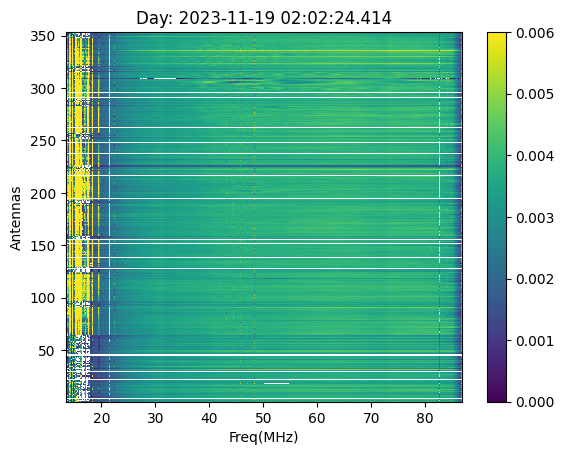

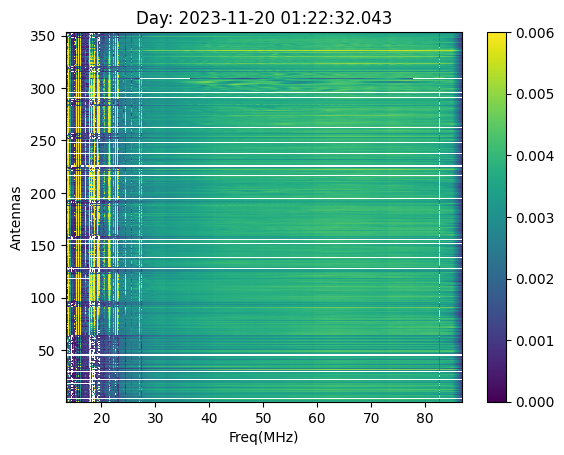

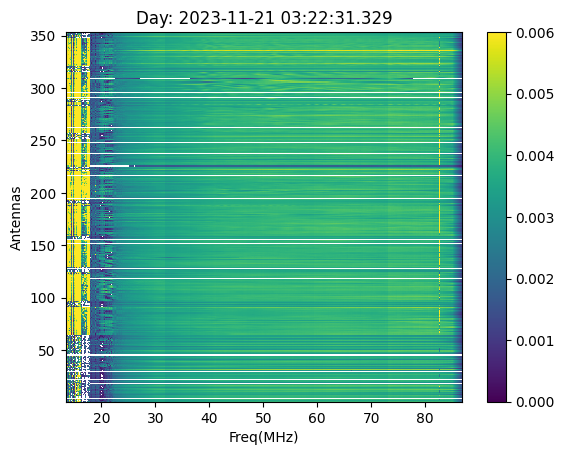

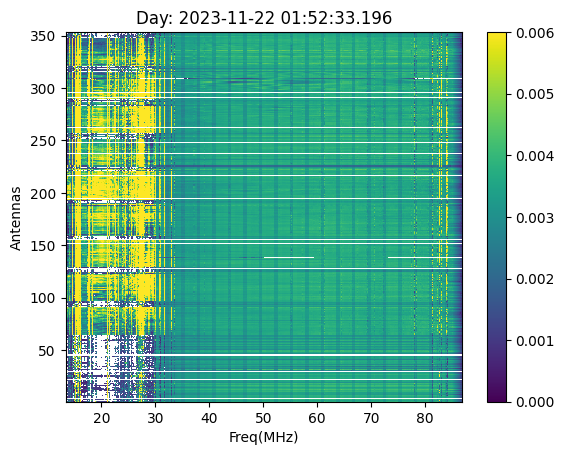

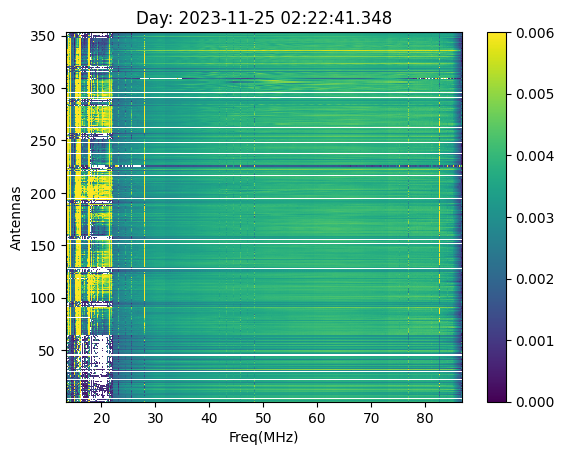

...

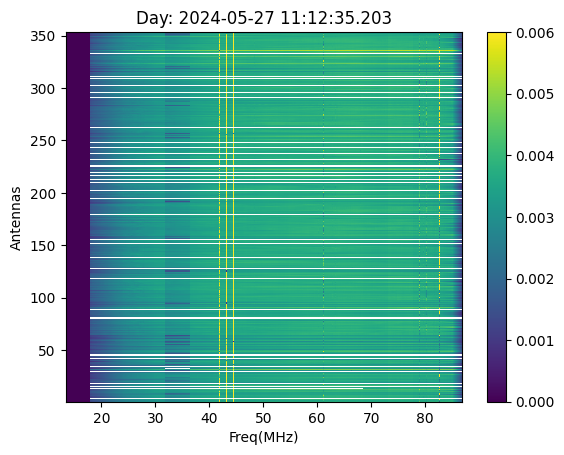

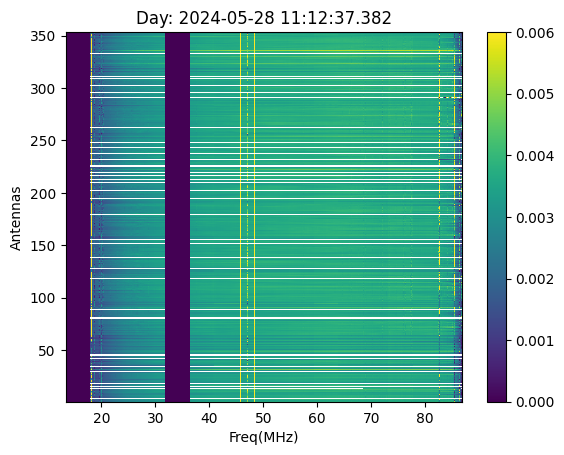

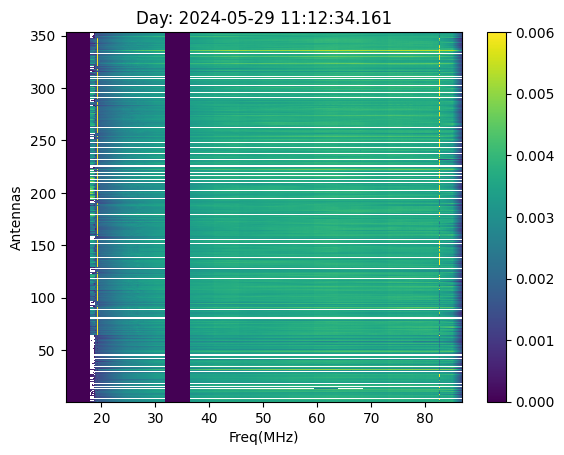

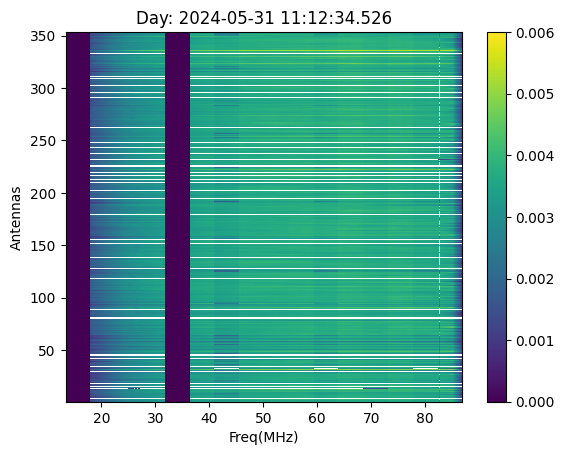

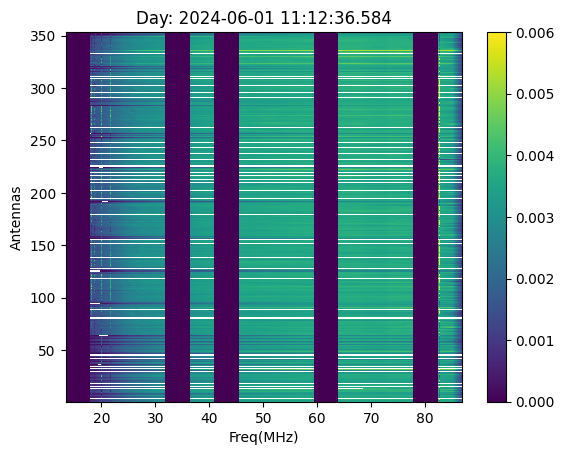

In [13]:
ants = np.linspace(1,353,352)
F,A = np.meshgrid(freqs,ants)
for i in range (np.shape(gain_sca)[0]):
    plt.figure()
    masked = np.ma.masked_where(flag[i,:,:,0]>0,gain_sca[i,:,:,0])
    plt.pcolormesh(F,A,np.abs(masked), vmin = 0, vmax=0.006)
    plt.colorbar()
    plt.ylabel('Antennas')
    plt.xlabel('Freq(MHz)')
    plt.title('Day: '+str(days[i]))

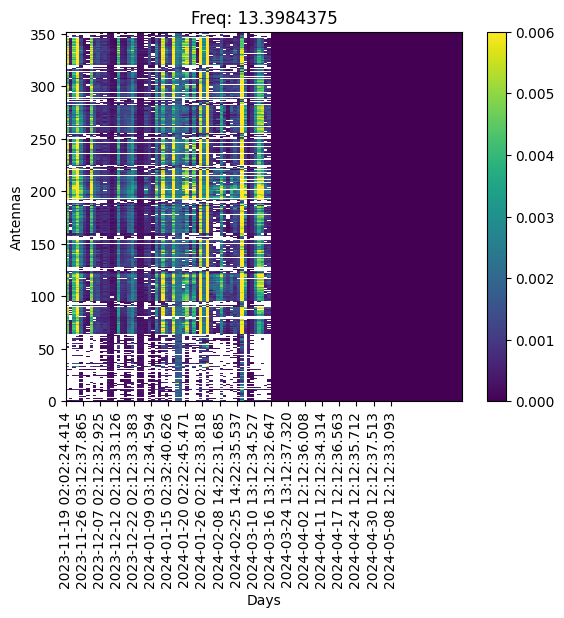

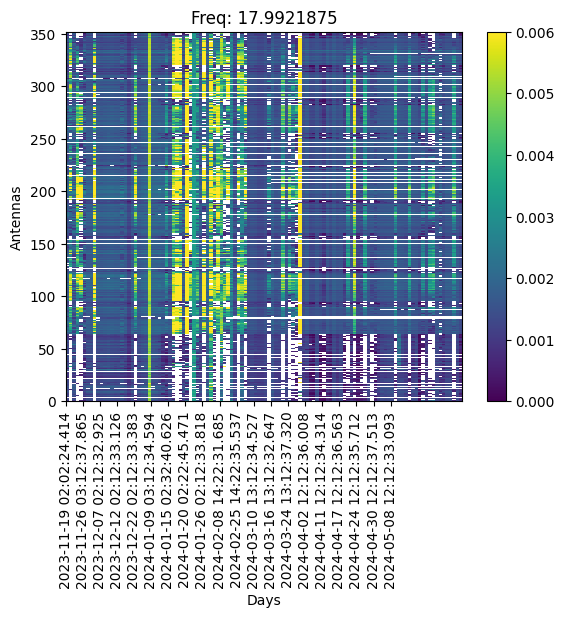

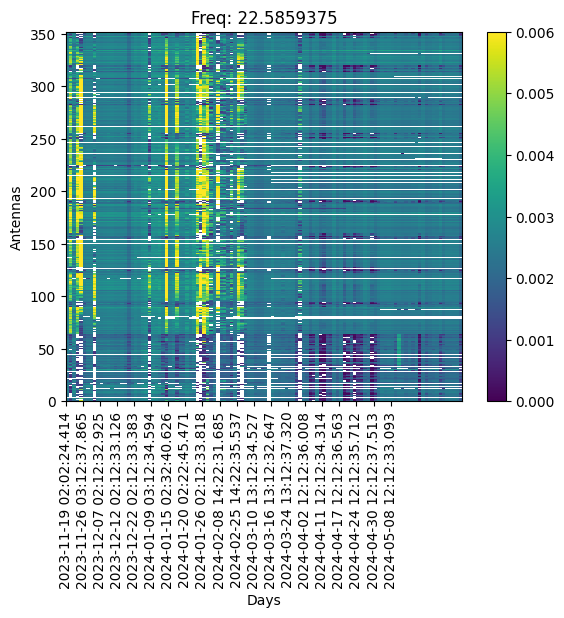

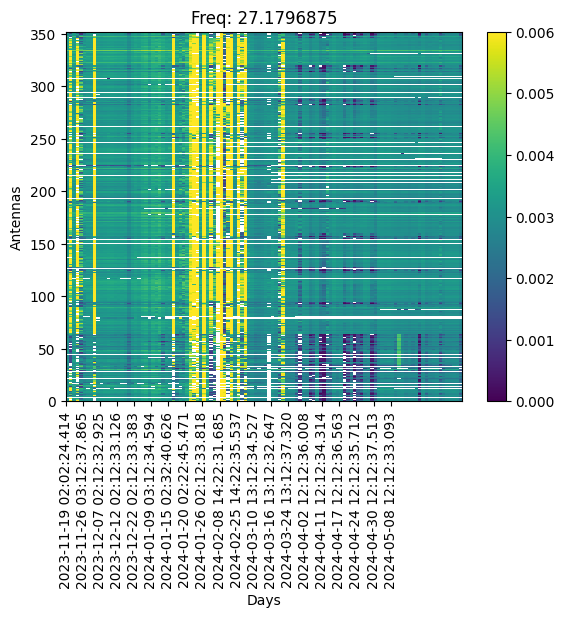

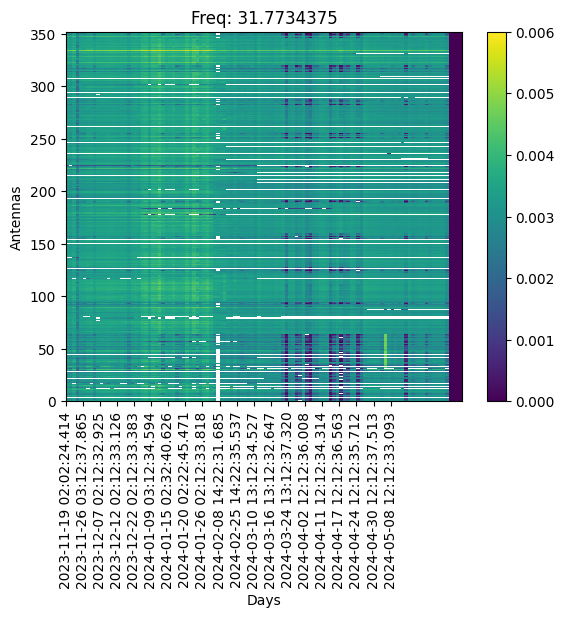

...

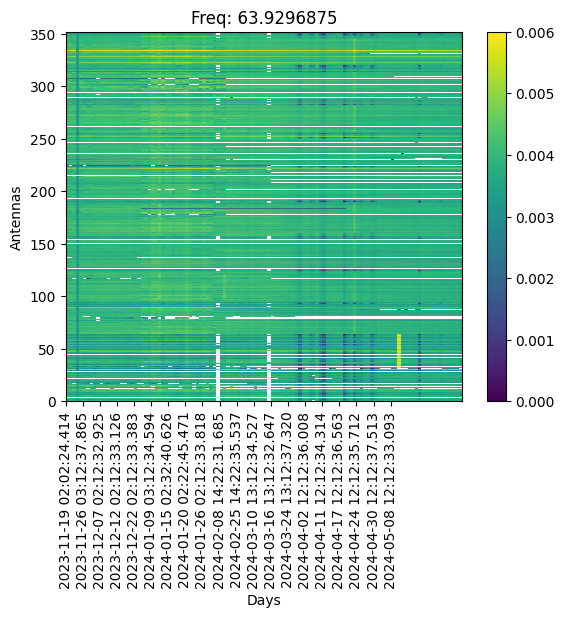

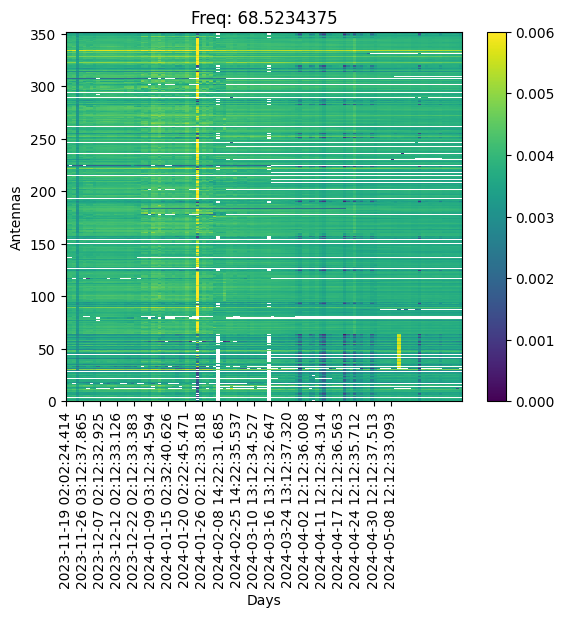

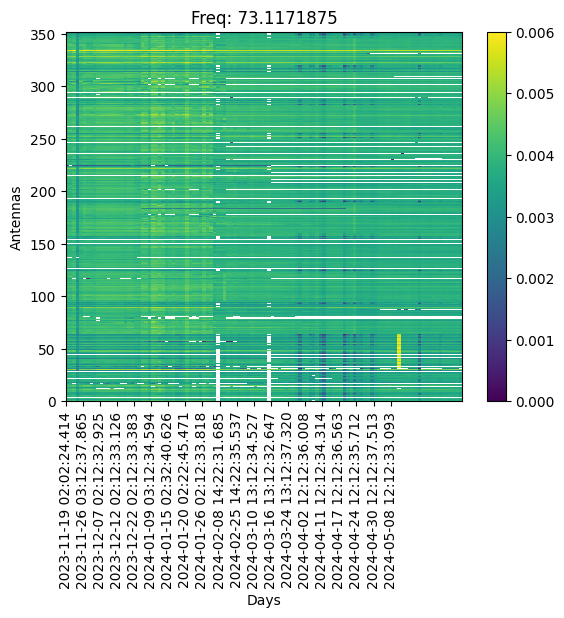

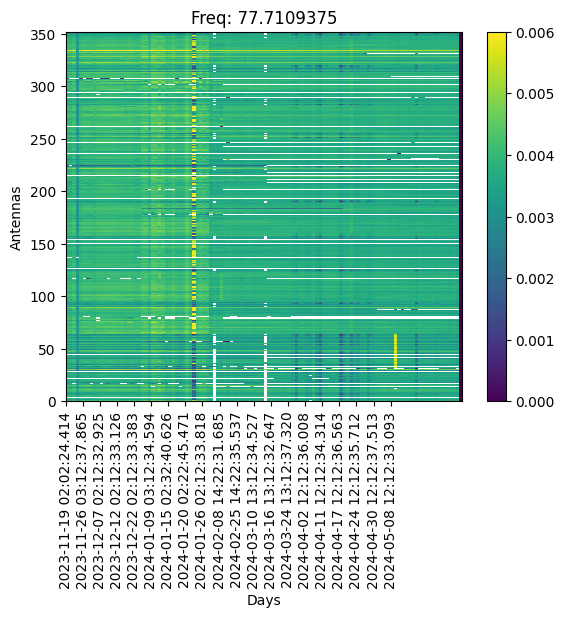

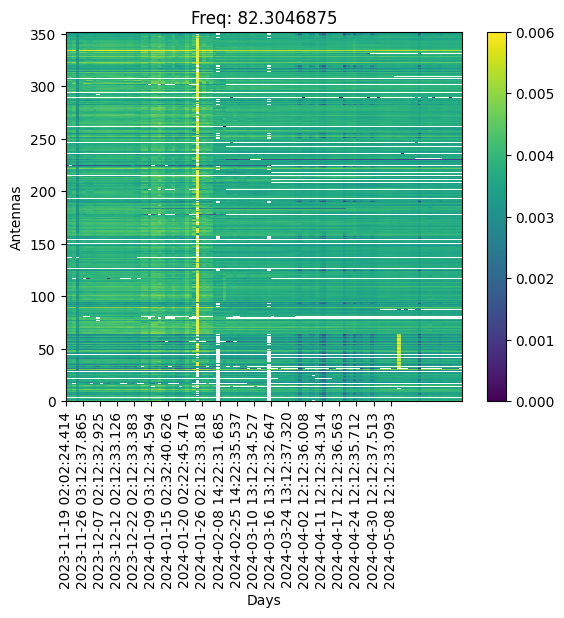

In [14]:
D,A = np.meshgrid(days,ants)
for i in range (int(np.shape(gain_sca)[2]/192)):
    plt.figure()
    masked = np.ma.masked_where(flag[:,:,i*192,0]>0,gain_sca[:,:,i*192,0])
    #plt.pcolormesh(F,A,np.abs(masked), vmin = 0, vmax=0.006)
    plt.pcolormesh(np.abs(masked.T), vmin = 0, vmax=0.006)
    plt.colorbar()
    plt.ylabel('Antennas')
    plt.xlabel('Days')
    #days_n = days.split(' ')
    xlabels = [days[0],days[5],days[10],days[15],days[20],days[25],days[30],days[35],days[40],days[45],days[50],days[55],days[60],days[65],days[70],days[75],days[80],days[85],days[90],days[95]]
    plt.xticks([0,5,10,15,20,25,30,35,40,45,50,55,60,65,70,75,80,85,90,95],xlabels, rotation='vertical')
    plt.title('Freq: '+str(freqs[i*192]))

In [ ]:
## excess code to test ionosphere
gain = t.getcol('CPARAM')
plt.plot(np.unwrap(np.angle(gain[0,:,0])))
plt.plot(np.unwrap(np.angle(gain[1,:,0])))

plt.plot(freqs/1e6,-(np.unwrap(np.angle(gain[0,:,0]))-np.unwrap(np.angle(gain[300,:,0])))*freqs/(8.45*10**9))
plt.ylabel('dTEC (TECU)')

plt.plot(np.abs(np.angle(gain[0,:,0])-np.angle(gain[2,:,0]))%2*np.pi)
#plt.plot(np.angle(gain[1,:,0]))
#plt.plot()
plt.xlim([0,100])